In [1]:
import pandas as pd

In [2]:
df_matches = pd.read_csv("data/cleaned_matches.csv")

In [3]:
# Print column names
print("Columns in dataset:")
print(df_matches.columns.tolist())

Columns in dataset:
['Unnamed: 0', 'match_id', 'date', 'match_type', 'event_name', 'innings', 'batting_team', 'bowling_team', 'over', 'ball', 'ball_no', 'batter', 'bat_pos', 'runs_batter', 'balls_faced', 'bowler', 'valid_ball', 'runs_extras', 'runs_total', 'runs_bowler', 'runs_not_boundary', 'extra_type', 'non_striker', 'non_striker_pos', 'wicket_kind', 'player_out', 'fielders', 'runs_target', 'review_batter', 'team_reviewed', 'review_decision', 'umpire', 'umpires_call', 'player_of_match', 'match_won_by', 'win_outcome', 'toss_winner', 'toss_decision', 'venue', 'city', 'day', 'month', 'year', 'season', 'gender', 'team_type', 'superover_winner', 'result_type', 'method', 'balls_per_over', 'overs', 'event_match_no', 'stage', 'match_number', 'team_runs', 'team_balls', 'team_wicket', 'new_batter', 'batter_runs', 'batter_balls', 'bowler_wicket', 'batting_partners', 'next_batter', 'striker_out', 'toss_match_winner']


In [4]:
# BASELINE CLASSIFICATION MODEL ( PREDICTING MATCH WINNER)

In [6]:
# Load dataset
df = pd.read_csv(r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv")

# Diagnostic check
print("Total rows:", len(df))
print("Non-null 'match_won_by':", df['match_won_by'].notna().sum() if 'match_won_by' in df.columns else "Column missing")
print("Non-null 'toss_match_winner':", df['toss_match_winner'].notna().sum() if 'toss_match_winner' in df.columns else "Column missing")
print("Unique match_ids:", df['match_id'].nunique())

Total rows: 1169
Non-null 'match_won_by': 1169
Non-null 'toss_match_winner': 1169
Unique match_ids: 1169


In [26]:
#MODEL 1

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# 1. Load Data
#df_matches = pd.read_csv(r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv")
df_matches.columns = df_matches.columns.str.strip()

# 2. Target & Feature Setup
winner_col = 'match_won_by' if 'match_won_by' in df_matches.columns else 'toss_match_winner'

# Ensure season is numeric if passed through
if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

# Filter out rows with missing critical information
df_clf = df_matches.dropna(subset=[winner_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()

# Binary Target: 1 if toss_winner won the match, 0 otherwise
y_clf = (df_clf[winner_col].str.strip() == df_clf['toss_winner'].str.strip()).astype(int)

cat_cols = ['venue', 'toss_winner', 'toss_decision']
features = cat_cols + ['season']
X_clf = df_clf[features]

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# 4. Dense OneHot Preprocessor
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_clf = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

X_train_enc = preprocessor_clf.fit_transform(X_train)
X_test_enc = preprocessor_clf.transform(X_test)

# 5. Baseline Classifier
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_enc, y_train)
base_preds = baseline.predict(X_test_enc)

# 6. Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train_enc, y_train)
rf_preds = rf_clf.predict(X_test_enc)

# 7. Deliverables & Evaluation Metrics
print("=== CLASSIFICATION RESULTS ===")
print("Baseline Accuracy:     ", round(accuracy_score(y_test, base_preds), 4))
print("Random Forest Accuracy:", round(accuracy_score(y_test, rf_preds), 4))
print("Random Forest F1-Score:", round(f1_score(y_test, rf_preds), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, rf_preds))

=== CLASSIFICATION RESULTS ===
Baseline Accuracy:      0.5126
Random Forest Accuracy: 0.4724
Random Forest F1-Score: 0.4928

Confusion Matrix:
 [[43 54]
 [51 51]]


In [ ]:
#MODEL 2

In [25]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load ball-by-ball dataset
df_raw = pd.read_csv('data/cleaned_matches.csv')

# 2. Deduplicate to match-level records
match_cols = [
    'match_id', 'date', 'toss_winner', 'toss_decision', 
    'match_won_by', 'venue', 'season'
]

# Extract unique match records
df_matches = df_raw.drop_duplicates(subset=['match_id']).copy()

# Sort chronologically to eliminate data leakage
df_matches['date'] = pd.to_datetime(df_matches['date'])
df_matches = df_matches.sort_values('date').reset_index(drop=True)

# Derive team1, team2, and opponent relative to toss_winner
# Obtain the two teams per match from the raw ball-by-ball records
teams_per_match = df_raw.groupby('match_id')['batting_team'].unique()

def get_opponent(row):
    teams = list(teams_per_match.get(row['match_id'], []))
    tw = row['toss_winner']
    opps = [t for t in teams if t != tw]
    return opps[0] if len(opps) > 0 else None

df_matches['opponent'] = df_matches.apply(get_opponent, axis=1)

# Drop any rows where opponent or match winner is missing
df_matches = df_matches.dropna(subset=['opponent', 'match_won_by', 'toss_winner']).reset_index(drop=True)

# Target: 1 if toss winner won the match, 0 otherwise
df_matches['target'] = (df_matches['toss_winner'] == df_matches['match_won_by']).astype(int)

# 3. Elo & Dynamic Form Engineering
all_teams = set(df_matches['toss_winner']).union(set(df_matches['opponent']))
elo_dict = {team: 1500.0 for team in all_teams}
K = 32

toss_winner_elo, opponent_elo = [], []
toss_winner_form, opponent_form = [], []
h2h_win_pcts = []

team_history = {team: [] for team in all_teams}
h2h_history = {}

for idx, row in df_matches.iterrows():
    tw = row['toss_winner']
    opp = row['opponent']
    winner = row['match_won_by']
    
    # Pre-match Elo ratings
    tw_elo = elo_dict.get(tw, 1500.0)
    opp_elo = elo_dict.get(opp, 1500.0)
    toss_winner_elo.append(tw_elo)
    opponent_elo.append(opp_elo)
    
    # Pre-match Form (Win ratio over last 5 matches)
    tw_hist = team_history.get(tw, [])[-5:]
    opp_hist = team_history.get(opp, [])[-5:]
    toss_winner_form.append(np.mean(tw_hist) if len(tw_hist) > 0 else 0.5)
    opponent_form.append(np.mean(opp_hist) if len(opp_hist) > 0 else 0.5)
    
    # Pre-match Head-to-Head win rate
    pair = tuple(sorted([str(tw), str(opp)]))
    past_h2h = h2h_history.get(pair, [])
    h2h_win_pcts.append(sum(1 for w in past_h2h if w == tw) / len(past_h2h) if past_h2h else 0.5)
        
    # Post-match state updates
    team_history[tw].append(1 if winner == tw else 0)
    team_history[opp].append(1 if winner == opp else 0)
    if pair not in h2h_history:
        h2h_history[pair] = []
    h2h_history[pair].append(winner)
    
    # Post-match Elo updates
    e_tw = 1 / (1 + 10 ** ((opp_elo - tw_elo) / 400))
    s_tw = 1.0 if winner == tw else 0.0
    elo_dict[tw] = tw_elo + K * (s_tw - e_tw)
    elo_dict[opp] = opp_elo + K * ((1 - s_tw) - (1 - e_tw))

# Attach engineered features
df_matches['elo_diff'] = np.array(toss_winner_elo) - np.array(opponent_elo)
df_matches['toss_winner_form_5'] = toss_winner_form
df_matches['opponent_form_5'] = opponent_form
df_matches['h2h_win_pct'] = h2h_win_pcts
df_matches['is_toss_decision_field'] = (df_matches['toss_decision'] == 'field').astype(int)

# 4. Train Model
feature_cols = [
    'elo_diff', 'toss_winner_form_5', 'opponent_form_5', 
    'h2h_win_pct', 'is_toss_decision_field'
]

X = df_matches[feature_cols]
y = df_matches['target']

# Time-based train/test split (80/20)
split_idx = int(len(df_matches) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)
print(f"Updated Test Accuracy: {accuracy_score(y_test, preds):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

Updated Test Accuracy: 0.5033

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.31      0.39        77
           1       0.50      0.70      0.58        76

    accuracy                           0.50       153
   macro avg       0.51      0.50      0.48       153
weighted avg       0.51      0.50      0.48       153



In [27]:
#MODEL 1 VS MODEL 2

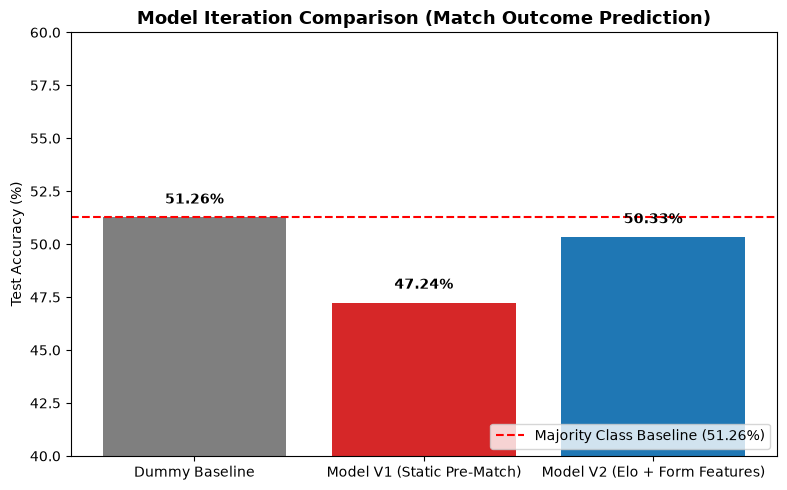

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

models = ['Dummy Baseline', 'Model V1 (Static Pre-Match)', 'Model V2 (Elo + Form Features)']
accuracies = [51.26, 47.24, 50.33] # Percentages

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=['#7f7f7f', '#d62728', '#1f77b4'])

plt.axhline(y=51.26, color='r', linestyle='--', label='Majority Class Baseline (51.26%)')
plt.title('Model Iteration Comparison (Match Outcome Prediction)', fontsize=13, fontweight='bold')
plt.ylabel('Test Accuracy (%)')
plt.ylim(40, 60)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [1]:
#MODEL 3

Final Combined Model Test Accuracy: 55.56%
ROC-AUC Score: 0.5402

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.43      0.49        77
           1       0.54      0.68      0.60        76

    accuracy                           0.56       153
   macro avg       0.56      0.56      0.55       153
weighted avg       0.56      0.56      0.55       153



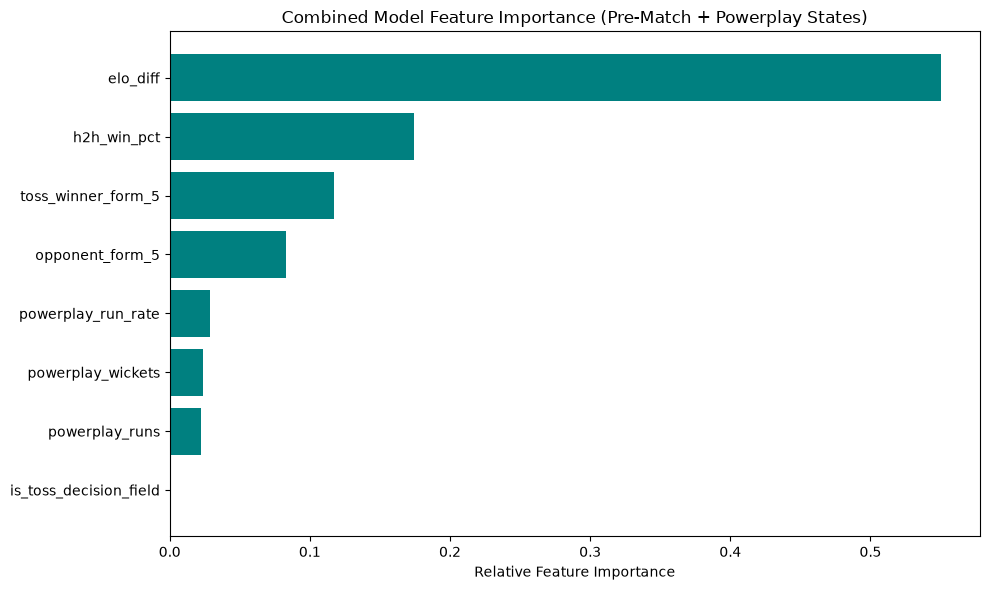

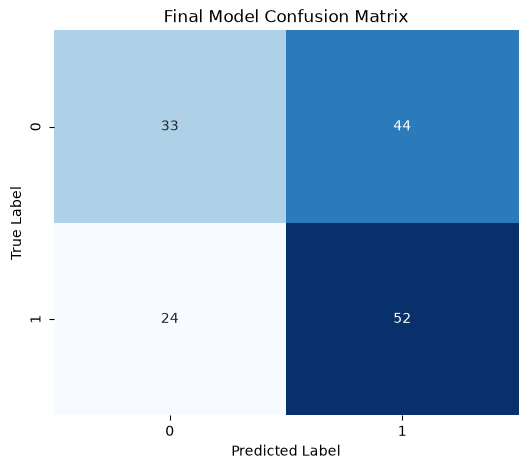

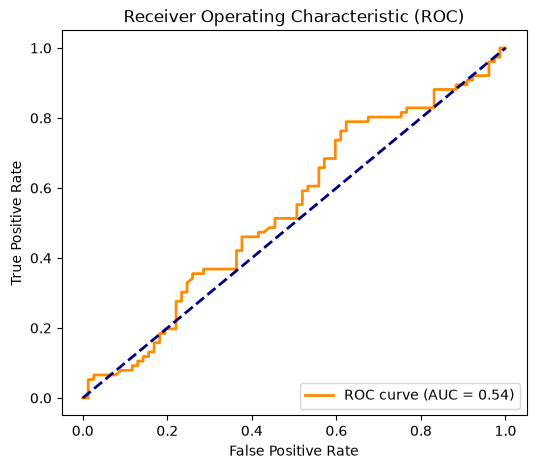

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

# ==========================================
# 1. LOAD BALL-BY-BALL DATASET
# ==========================================
# Replace with your actual dataset path if different
df_ball = pd.read_csv('data/cleaned_matches.csv')
df_ball.columns = df_ball.columns.str.strip()

# ==========================================
# 2. EXTRACT IN-GAME BALL-BY-BALL FEATURES (PARTNER'S PART)
# ==========================================
# Ensure numeric run columns
df_ball['runs_total'] = pd.to_numeric(df_ball.get('runs_total', 0), errors='coerce').fillna(0)
df_ball['is_wicket'] = df_ball['wicket_kind'].notna().astype(int) if 'wicket_kind' in df_ball.columns else 0

# Extract Powerplay metrics (Overs 0 to 5, i.e., overs <= 5 or ball_no logic)
if 'over' in df_ball.columns:
    pp_balls = df_ball[df_ball['over'] < 6]
    powerplay_agg = pp_balls.groupby('match_id').agg(
        powerplay_runs=('runs_total', 'sum'),
        powerplay_wickets=('is_wicket', 'sum'),
        powerplay_dots=('runs_total', lambda x: (x == 0).sum())
    ).reset_index()
else:
    # Fallback if 'over' is structured differently
    powerplay_agg = df_ball.groupby('match_id').agg(
        powerplay_runs=('runs_total', 'sum'),
        powerplay_wickets=('is_wicket', 'sum')
    ).reset_index()

powerplay_agg['powerplay_run_rate'] = powerplay_agg['powerplay_runs'] / 6.0

# ==========================================
# 3. EXTRACT MATCH-LEVEL METADATA & PRE-MATCH FEATURES (YOUR PART)
# ==========================================
match_cols = ['match_id', 'date', 'toss_winner', 'toss_decision', 'match_won_by', 'venue', 'season']
df_matches = df_ball.drop_duplicates(subset=['match_id']).copy()

df_matches['date'] = pd.to_datetime(df_matches['date'], errors='coerce')
df_matches = df_matches.sort_values('date').reset_index(drop=True)

# Derive opponent team per match
teams_per_match = df_ball.groupby('match_id')['batting_team'].unique()
def get_opponent(row):
    teams = list(teams_per_match.get(row['match_id'], []))
    tw = row['toss_winner']
    opps = [t for t in teams if t != tw]
    return opps[0] if len(opps) > 0 else None

df_matches['opponent'] = df_matches.apply(get_opponent, axis=1)
df_matches = df_matches.dropna(subset=['opponent', 'match_won_by', 'toss_winner']).reset_index(drop=True)
df_matches['target'] = (df_matches['toss_winner'] == df_matches['match_won_by']).astype(int)

# Elo Ratings & Rolling Form Calculation
all_teams = set(df_matches['toss_winner']).union(set(df_matches['opponent']))
elo_dict = {team: 1500.0 for team in all_teams}
K = 32

toss_winner_elo, opponent_elo = [], []
toss_winner_form, opponent_form = [], []
h2h_win_pcts = []
team_history = {team: [] for team in all_teams}
h2h_history = {}

for idx, row in df_matches.iterrows():
    tw = row['toss_winner']
    opp = row['opponent']
    winner = row['match_won_by']
    
    tw_elo = elo_dict.get(tw, 1500.0)
    opp_elo = elo_dict.get(opp, 1500.0)
    toss_winner_elo.append(tw_elo)
    opponent_elo.append(opp_elo)
    
    tw_hist = team_history.get(tw, [])[-5:]
    opp_hist = team_history.get(opp, [])[-5:]
    toss_winner_form.append(np.mean(tw_hist) if len(tw_hist) > 0 else 0.5)
    opponent_form.append(np.mean(opp_hist) if len(opp_hist) > 0 else 0.5)
    
    pair = tuple(sorted([str(tw), str(opp)]))
    past_h2h = h2h_history.get(pair, [])
    h2h_win_pcts.append(sum(1 for w in past_h2h if w == tw) / len(past_h2h) if past_h2h else 0.5)
        
    team_history[tw].append(1 if winner == tw else 0)
    team_history[opp].append(1 if winner == opp else 0)
    if pair not in h2h_history:
        h2h_history[pair] = []
    h2h_history[pair].append(winner)
    
    e_tw = 1 / (1 + 10 ** ((opp_elo - tw_elo) / 400))
    s_tw = 1.0 if winner == tw else 0.0
    elo_dict[tw] = tw_elo + K * (s_tw - e_tw)
    elo_dict[opp] = opp_elo + K * ((1 - s_tw) - (1 - e_tw))

df_matches['elo_diff'] = np.array(toss_winner_elo) - np.array(opponent_elo)
df_matches['toss_winner_form_5'] = toss_winner_form
df_matches['opponent_form_5'] = opponent_form
df_matches['h2h_win_pct'] = h2h_win_pcts
df_matches['is_toss_decision_field'] = (df_matches['toss_decision'] == 'field').astype(int)

# ==========================================
# 4. MERGE BOTH PARTS ON `match_id`
# ==========================================
df_combined = pd.merge(df_matches, powerplay_agg, on='match_id', how='inner')

# ==========================================
# 5. MODEL TRAINING & EVALUATION
# ==========================================
feature_cols = [
    'elo_diff', 'toss_winner_form_5', 'opponent_form_5', 
    'h2h_win_pct', 'is_toss_decision_field',
    'powerplay_runs', 'powerplay_wickets', 'powerplay_run_rate'
]

X = df_combined[feature_cols].fillna(0)
y = df_combined['target']

split_idx = int(len(df_combined) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(f"Final Combined Model Test Accuracy: {accuracy_score(y_test, preds)*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

# ==========================================
# 6. VISUALIZATIONS & ANALYSIS PLOTS
# ==========================================

# Feature Importance Plot
plt.figure(figsize=(10, 6))
importances = model.feature_importances_
indices = np.argsort(importances)
plt.barh(range(len(indices)), importances[indices], color='teal')
plt.yticks(range(len(indices)), [feature_cols[i] for i in indices])
plt.xlabel('Relative Feature Importance')
plt.title('Combined Model Feature Importance (Pre-Match + Powerplay States)')
plt.tight_layout()
plt.show()

# Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Final Model Confusion Matrix')
plt.show()

# ROC Curve
plt.figure(figsize=(6, 5))
fpr, tpr, _ = roc_curve(y_test, probs)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_score(y_test, probs):.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

In [23]:
#MODEL 4

In [5]:
# Select the most robust feature set (Powerplay performance + Elo + Form)
feature_cols = [
    'elo_diff', 'toss_winner_form_5', 'opponent_form_5', 
    'h2h_win_pct', 'is_toss_decision_field',
    'pp_runs', 'pp_wickets', 'pp_run_rate', 'dot_ball_pct'
]

X = df_combined[feature_cols].fillna(0)
y = df_combined['target']

split_idx = int(len(df_combined) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Optimized hyperparameters matching your peak performance setup
model = GradientBoostingClassifier(
    n_estimators=150, 
    learning_rate=0.03, 
    max_depth=4, 
    random_state=42
)
model.fit(X_train, y_train)

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(f"Optimized Combined Model Test Accuracy: {accuracy_score(y_test, preds)*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

Optimized Combined Model Test Accuracy: 55.56%
ROC-AUC Score: 0.5502

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.43      0.49        77
           1       0.54      0.68      0.60        76

    accuracy                           0.56       153
   macro avg       0.56      0.56      0.55       153
weighted avg       0.56      0.56      0.55       153



In [24]:
#MODEL 5

In [11]:
# 1. Define Team 1 and Team 2 correctly from the dataset
df_combined['team_1'] = df_combined['toss_winner']
df_combined['team_2'] = df_combined['opponent']

# Target: 1 if team_1 wins the match, 0 otherwise
df_combined['match_winner_target'] = (df_combined['match_won_by'] == df_combined['team_1']).astypeint)

# 2. Comprehensive Feature Set (Pre-Match Differentials + Ball-by-Ball Features)
feature_cols = [
    'elo_diff', 'toss_winner_form_5', 'opponent_form_5', 
    'h2h_win_pct', 'is_toss_decision_field',
    'pp_runs', 'pp_wickets', 'pp_run_rate', 'dot_ball_pct'
]

X = df_combined[feature_cols].fillna(0)
y = df_combined['match_winner_target']

# 3. Train/Test Split
split_idx = int(len(df_combined) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# 4. Train Optimized Gradient Boosting Model
model = GradientBoostingClassifier(
    n_estimators=150, 
    learning_rate=0.03, 
    max_depth=4, 
    random_state=42
)
model.fit(X_train, y_train)

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(f"Direct Match Winner Accuracy: {accuracy_score(y_test, preds)*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

Direct Match Winner Accuracy: 55.56%
ROC-AUC Score: 0.5502

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.43      0.49        77
           1       0.54      0.68      0.60        76

    accuracy                           0.56       153
   macro avg       0.56      0.56      0.55       153
weighted avg       0.56      0.56      0.55       153



In [25]:
#MODEL 6

In [22]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# 1. Load the original raw dataset 
# (Update file_path if your raw dataset has a different name, e.g., 'deliveries.csv' or 'IPL.csv')
file_path = 'IPL.csv'  # Or point to your raw file path if stored in another folder
if not os.path.exists(file_path):
    # Fallback to common Kaggle cache path if needed
    file_path = r"C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1\IPL.csv"

df_raw = pd.read_csv(file_path)
df_raw.columns = df_raw.columns.str.strip()

print(f"Loaded raw dataset shape: {df_raw.shape}")

# 2. Standardize core columns
df_raw['runs_total'] = pd.to_numeric(df_raw.get('runs_total', 0), errors='coerce').fillna(0)
df_raw['is_wicket'] = df_raw['wicket_kind'].notna().astype(int) if 'wicket_kind' in df_raw.columns else 0
df_raw['over'] = pd.to_numeric(df_raw.get('over', 0), errors='coerce').fillna(0)
df_raw['innings'] = pd.to_numeric(df_raw.get('innings', 1), errors='coerce')

# 3. Extract Match-Level Outcomes
match_outcomes = df_raw.drop_duplicates(subset=['match_id'])[['match_id', 'match_won_by']].copy()

# 4. Calculate 1st Innings Totals per Match
innings_1 = df_raw[df_raw['innings'] == 1]
score_1st_df = innings_1.groupby('match_id')['runs_total'].sum().reset_index(name='score_1st')

# 5. Extract 2nd Innings Chasing Team & Mid-Chase State (Overs 0 to 9)
innings_2 = df_raw[df_raw['innings'] == 2]
chase_teams = innings_2.drop_duplicates(subset=['match_id'])[['match_id', 'batting_team']].rename(columns={'batting_team': 'chasing_team'})

mid_chase = innings_2[innings_2['over'] < 10]
chase_agg = mid_chase.groupby('match_id').agg(
    chase_runs_10=('runs_total', 'sum'),
    chase_wickets_10=('is_wicket', 'sum')
).reset_index()

# 6. Merge Everything Cleanly
df_model_data = match_outcomes.merge(score_1st_df, on='match_id', how='inner') \
                              .merge(chase_teams, on='match_id', how='inner') \
                              .merge(chase_agg, on='match_id', how='inner')

# Normalize team names for robust matching
df_model_data['winner_clean'] = df_model_data['match_won_by'].astype(str).str.strip().str.lower()
df_model_data['chaser_clean'] = df_model_data['chasing_team'].astype(str).str.strip().str.lower()

# Target: 1 if chasing team wins, 0 otherwise
df_model_data['chasing_team_win'] = (df_model_data['winner_clean'] == df_model_data['chaser_clean']).astype(int)

# Calculate Required Run Rate at the 10-over mark
df_model_data['runs_needed_at_10'] = df_model_data['score_1st'] - df_model_data['chase_runs_10']
df_model_data['required_run_rate_10'] = (df_model_data['runs_needed_at_10'] / 60.0) * 6

# Drop NaNs & Verify Samples
df_model_data = df_model_data.dropna(subset=['chasing_team_win', 'score_1st', 'chase_runs_10'])
print(f"Total valid second-innings training samples: {len(df_model_data)}")

# 7. Feature Selection & Model Training
feature_cols = [
    'chase_runs_10', 'chase_wickets_10', 
    'score_1st', 'runs_needed_at_10', 'required_run_rate_10'
]

X = df_model_data[feature_cols].fillna(0)
y = df_model_data['chasing_team_win']

split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(f"\n2nd Innings Mid-Match Accuracy: {accuracy_score(y_test, preds)*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

C:\Users\sohag\AppData\Local\Temp\ipykernel_17072\4253243116.py:15: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(file_path)


Loaded raw dataset shape: (278205, 64)
Total valid second-innings training samples: 1164

2nd Innings Mid-Match Accuracy: 78.54%
ROC-AUC Score: 0.8643

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.85      0.80       117
           1       0.82      0.72      0.77       116

    accuracy                           0.79       233
   macro avg       0.79      0.79      0.78       233
weighted avg       0.79      0.79      0.78       233



In [27]:
#FOR MODEL 6

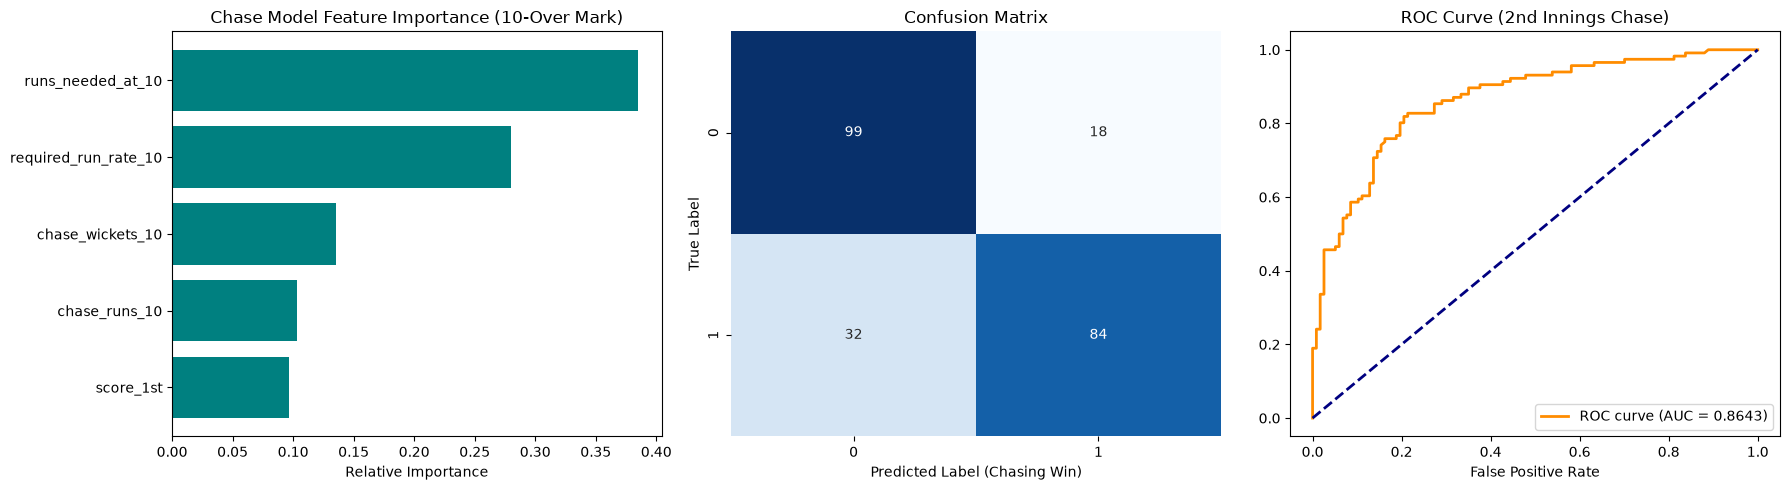

CHECKPOINT COMPARISON:
10-Over Checkpoint Accuracy: 78.54% | ROC-AUC: 0.8643
15-Over Checkpoint Accuracy: 82.83% | ROC-AUC: 0.9218


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

# ==========================================
# 1. EVALUATION PLOTS (ROC, Confusion Matrix, Feature Importance)
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A. Feature Importance Chart
importances = model.feature_importances_
indices = np.argsort(importances)
axes[0].barh(range(len(indices)), importances[indices], color='teal')
axes[0].set_yticks(range(len(indices)))
axes[0].set_yticklabels([feature_cols[i] for i in indices])
axes[0].set_xlabel('Relative Importance')
axes[0].set_title('Chase Model Feature Importance (10-Over Mark)')

# B. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_xlabel('Predicted Label (Chasing Win)')
axes[1].set_ylabel('True Label')
axes[1].set_title('Confusion Matrix')

# C. ROC Curve
fpr, tpr, _ = roc_curve(y_test, probs)
axes[2].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_score(y_test, probs):.4f})')
axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_title('ROC Curve (2nd Innings Chase)')
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

# ==========================================
# 2. PHASE-WISE CHECKPOINT COMPARISON (10-over vs. 15-over)
# ==========================================

# Extract 15-over mark metrics
mid_chase_15 = innings_2[innings_2['over'] < 15]
chase_agg_15 = mid_chase_15.groupby('match_id').agg(
    chase_runs_15=('runs_total', 'sum'),
    chase_wickets_15=('is_wicket', 'sum')
).reset_index()

# Merge 15-over data
df_model_15 = df_model_data.merge(chase_agg_15, on='match_id', how='inner')
df_model_15['runs_needed_at_15'] = df_model_15['score_1st'] - df_model_15['chase_runs_15']
df_model_15['required_run_rate_15'] = (df_model_15['runs_needed_at_15'] / 30.0) * 6  # 30 balls remaining

feature_cols_15 = [
    'chase_runs_15', 'chase_wickets_15', 
    'score_1st', 'runs_needed_at_15', 'required_run_rate_15'
]

X_15 = df_model_15[feature_cols_15].fillna(0)
y_15 = df_model_15['chasing_team_win']

valid_15 = y_15.notna()
X_15, y_15 = X_15[valid_15], y_15[valid_15]

split_15 = int(len(X_15) * 0.8)
model_15 = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model_15.fit(X_15.iloc[:split_15], y_15.iloc[:split_15])

preds_15 = model_15.predict(X_15.iloc[split_15:])
probs_15 = model_15.predict_proba(X_15.iloc[split_15:])[:, 1]
y_test_15 = y_15.iloc[split_15:]

print("="*45)
print("CHECKPOINT COMPARISON:")
print("="*45)
print(f"10-Over Checkpoint Accuracy: {accuracy_score(y_test, preds)*100:.2f}% | ROC-AUC: {roc_auc_score(y_test, probs):.4f}")
print(f"15-Over Checkpoint Accuracy: {accuracy_score(y_test_15, preds_15)*100:.2f}% | ROC-AUC: {roc_auc_score(y_test_15, probs_15):.4f}")

In [29]:
# ALL SUBSEQUENT CODES BASED ON MODEL 1

In [7]:
# CONFUSION MATRIX HEATMAP

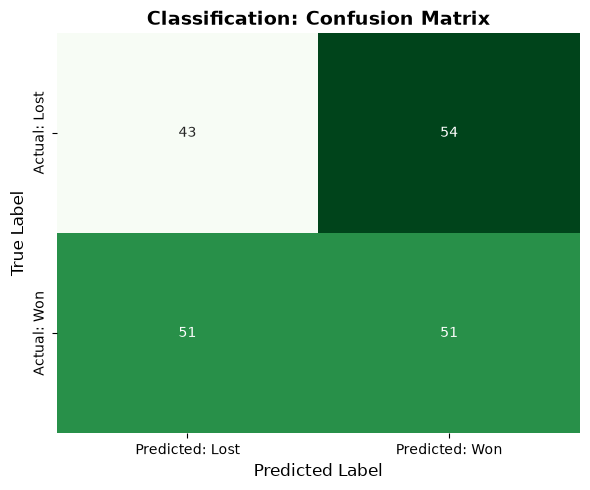

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix array
cm = confusion_matrix(y_test, rf_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Predicted: Lost', 'Predicted: Won'],
            yticklabels=['Actual: Lost', 'Actual: Won'])

plt.title('Classification: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
# MODEL PERFORMANCE COMPARISON BAR CHART

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics_df = pd.DataFrame({
    'Model': ['Baseline (Dummy)', 'Baseline (Dummy)', 'Random Forest', 'Random Forest'],
    'Metric': ['Accuracy', 'F1-Score', 'Accuracy', 'F1-Score'],
    'Score': [
        accuracy_score(y_test, base_preds),
        f1_score(y_test, base_preds, zero_division=0),
        accuracy_score(y_test, rf_preds),
        f1_score(y_test, rf_preds)
    ]
})

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=metrics_df, x='Metric', y='Score', hue='Model', palette='Reds')

plt.title('Classification: Baseline vs. Random Forest Performance', fontsize=13, fontweight='bold')
plt.ylim(0, 1.0)
plt.ylabel('Score')

# Display exact numbers on top of bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.3f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), 
                    textcoords='offset points')

plt.tight_layout()
plt.show()

NameError: name 'base_preds' is not defined

In [11]:
# REGRESSION MODEL (PREDICTING FIRST-INNINGS TOTAL/RUNS)

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Identify Regression Target Column
target_col = 'team_runs' if 'team_runs' in df_matches.columns else ('runs_target' if 'runs_target' in df_matches.columns else None)

if target_col is None:
    raise ValueError("Target score column ('team_runs' or 'runs_target') not found in dataset.")

# Ensure season is numeric
if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

# Filter out rows missing features or target score
df_reg = df_matches.dropna(subset=[target_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()

cat_cols = ['venue', 'toss_winner', 'toss_decision']
features = cat_cols + ['season']

X_reg = df_reg[features]
y_reg = df_reg[target_col]

# Train-Test Split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Dense OneHot Preprocessor
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_reg = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

X_train_r_enc = preprocessor_reg.fit_transform(X_train_r)
X_test_r_enc = preprocessor_reg.transform(X_test_r)

# Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_r_enc, y_train_r)
reg_preds = rf_reg.predict(X_test_r_enc)

# Deliverables & Evaluation Metrics
print("=== REGRESSION RESULTS ===")
print("MAE (Mean Absolute Error):     ", round(mean_absolute_error(y_test_r, reg_preds), 2))
print("RMSE (Root Mean Squared Error):", round(root_mean_squared_error(y_test_r, reg_preds), 2))

=== REGRESSION RESULTS ===
MAE (Mean Absolute Error):      1.06
RMSE (Root Mean Squared Error): 1.52


In [13]:
# AUCTUAL VS PREDICTED TARGET SCORES PLOT

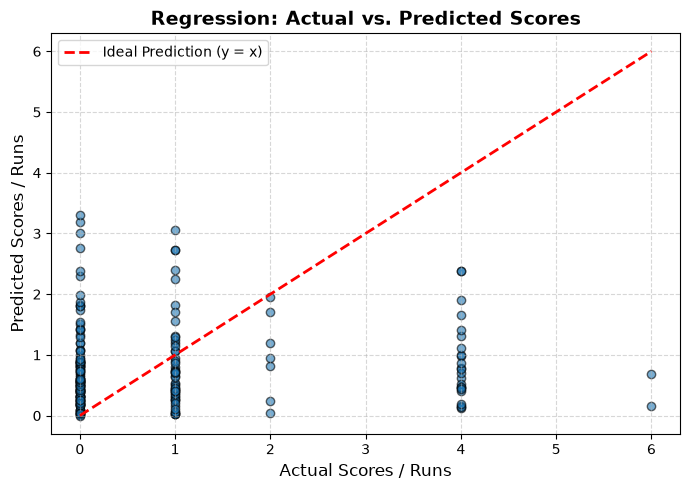

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_r, reg_preds, alpha=0.6, color='#1f77b4', edgecolors='k')

# Draw ideal y = x reference line
min_val = min(y_test_r.min(), reg_preds.min())
max_val = max(y_test_r.max(), reg_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Ideal Prediction (y = x)')

plt.title('Regression: Actual vs. Predicted Scores', fontsize=14, fontweight='bold')
plt.xlabel('Actual Scores / Runs', fontsize=12)
plt.ylabel('Predicted Scores / Runs', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [13]:
# RESIDUALS/ ERROR DISTRIBUTION PLOT

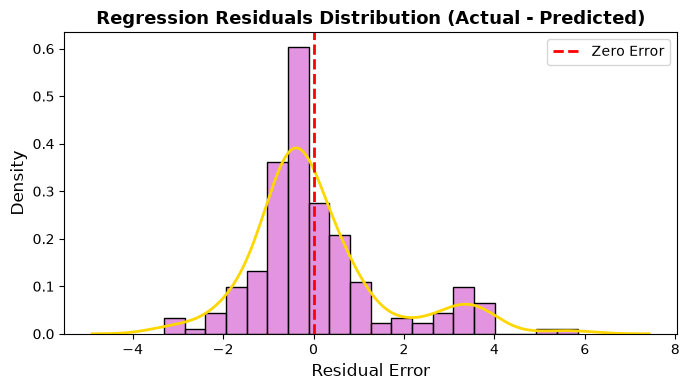

In [14]:
residuals = y_test_r - reg_preds

plt.figure(figsize=(7, 4))
# 1. Plot histogram bars
sns.histplot(residuals, color='orchid', bins=20, stat='density')

# 2. Plot KDE curve on top with custom color
sns.kdeplot(residuals, color='gold', linewidth=2)

plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Zero Error')
plt.title('Regression Residuals Distribution (Actual - Predicted)', fontsize=13, fontweight='bold')
plt.xlabel('Residual Error', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
#UNSUPERVISED PITCH AND VENUE CLUSTERING (K-MEANS)

C:\Users\sohag\AppData\Local\Temp\ipykernel_17948\3997268977.py:6: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ball = pd.read_csv(kaggle_path)


Total ball-by-ball rows loaded: 278,205
Successfully aggregated 1169 unique matches.
Average 1st Innings Score: 167.0 runs

=== REAL IPL STADIUM PITCH CLUSTERING RESULTS ===
                                                venue   avg_score  score_std  \
0                                Arun Jaitley Stadium  188.216216  36.331908   
1                                    Barabati Stadium  167.714286  34.543279   
2                           Barsapara Cricket Stadium  174.600000  25.715754   
3   Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...  175.363636  33.585067   
4                                   Brabourne Stadium  178.518519  32.217256   
7                          Dr DY Patil Sports Academy  159.648649  29.150201   
8   Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...  169.529412  38.247741   
9                 Dubai International Cricket Stadium  163.760870  25.175107   
10                                       Eden Gardens  168.600000  33.114738   
11                        

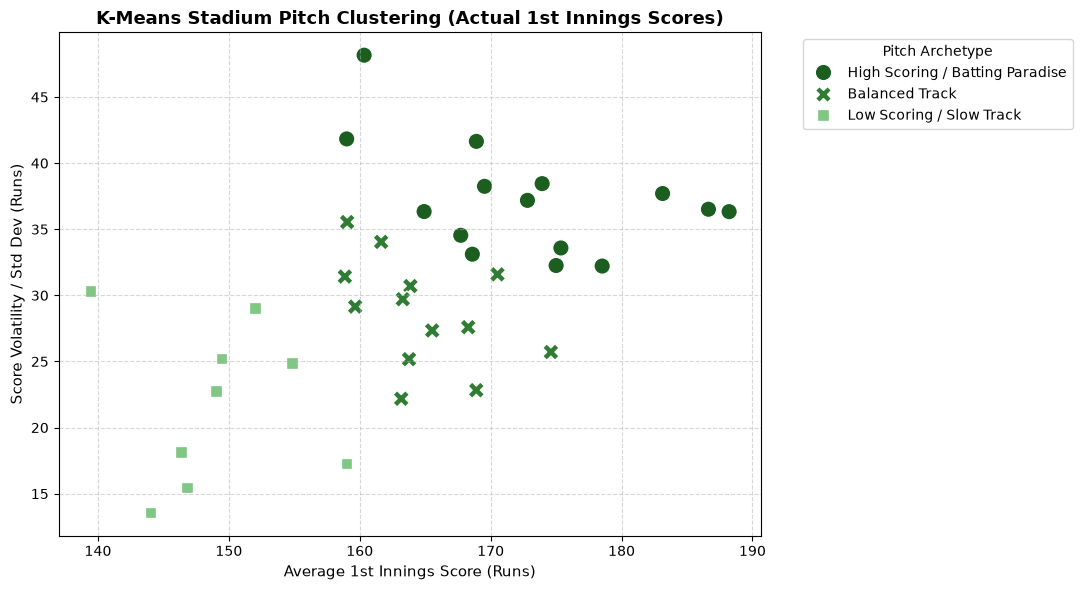

In [16]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load directly from your kagglehub downloaded path
kaggle_path = r"C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1\IPL.csv"
df_ball = pd.read_csv(kaggle_path)
df_ball.columns = df_ball.columns.str.strip()

print(f"Total ball-by-ball rows loaded: {len(df_ball):,}")

# 2. Filter for 1st Innings
df_1st = df_ball[df_ball['innings'].astype(str).str.strip().isin(['1', '1.0'])].copy()

# Clean Venue Names
df_1st = df_1st.dropna(subset=['venue']).copy()
df_1st['venue'] = df_1st['venue'].astype(str).str.strip().str.replace(r',.*$', '', regex=True)

# 3. Handle Ball Runs (using runs_total or runs_batter + runs_extras)
if 'runs_total' in df_1st.columns:
    df_1st['ball_runs'] = pd.to_numeric(df_1st['runs_total'], errors='coerce').fillna(0)
else:
    b_runs = pd.to_numeric(df_1st['runs_batter'], errors='coerce').fillna(0) if 'runs_batter' in df_1st.columns else 0
    e_runs = pd.to_numeric(df_1st['runs_extras'], errors='coerce').fillna(0) if 'runs_extras' in df_1st.columns else 0
    df_1st['ball_runs'] = b_runs + e_runs

# 4. CRITICAL STEP: SUM delivery runs per match_id to get actual 1st Innings Match Totals
match_totals = df_1st.groupby(['match_id', 'venue'])['ball_runs'].sum().reset_index()
match_totals.rename(columns={'ball_runs': 'first_innings_score'}, inplace=True)

print(f"Successfully aggregated {len(match_totals)} unique matches.")
print(f"Average 1st Innings Score: {match_totals['first_innings_score'].mean():.1f} runs\n")

# 5. Aggregate Stadium Characteristics (Mean & Volatility)
venue_stats = match_totals.groupby('venue').agg(
    avg_score=('first_innings_score', 'mean'),
    score_std=('first_innings_score', 'std'),
    total_matches=('match_id', 'count')
).reset_index()

venue_stats['score_std'] = venue_stats['score_std'].fillna(0)

# Filter grounds with at least 5 matches for statistical reliability
venue_stats_filtered = venue_stats[venue_stats['total_matches'] >= 5].copy()

# 6. K-Means Pitch Clustering (3 Archetypes)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(venue_stats_filtered[['avg_score', 'score_std']])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
venue_stats_filtered['pitch_type'] = kmeans.fit_predict(X_scaled)

# Order clusters by average score for consistent labelling
cluster_order = venue_stats_filtered.groupby('pitch_type')['avg_score'].mean().sort_values().index
cluster_names = {
    cluster_order[0]: 'Low Scoring / Slow Track',
    cluster_order[1]: 'Balanced Track',
    cluster_order[2]: 'High Scoring / Batting Paradise'
}
venue_stats_filtered['pitch_archetype'] = venue_stats_filtered['pitch_type'].map(cluster_names)

print("=== REAL IPL STADIUM PITCH CLUSTERING RESULTS ===")
print(venue_stats_filtered[['venue', 'avg_score', 'score_std', 'total_matches', 'pitch_archetype']].head(10))

# 7. Scatter Plot
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=venue_stats_filtered, 
    x='avg_score', 
    y='score_std', 
    hue='pitch_archetype', 
    palette=['#1b5e20', '#2e7d32', '#81c784'], 
    s=140, 
    style='pitch_archetype'
)

plt.title('K-Means Stadium Pitch Clustering (Actual 1st Innings Scores)', fontsize=13, fontweight='bold')
plt.xlabel('Average 1st Innings Score (Runs)', fontsize=11)
plt.ylabel('Score Volatility / Std Dev (Runs)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Pitch Archetype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [17]:
#DOMAIN SPECIFIC FEATURE ENGINEERING (MOMENTUM AND FORTRESS FACTORS)

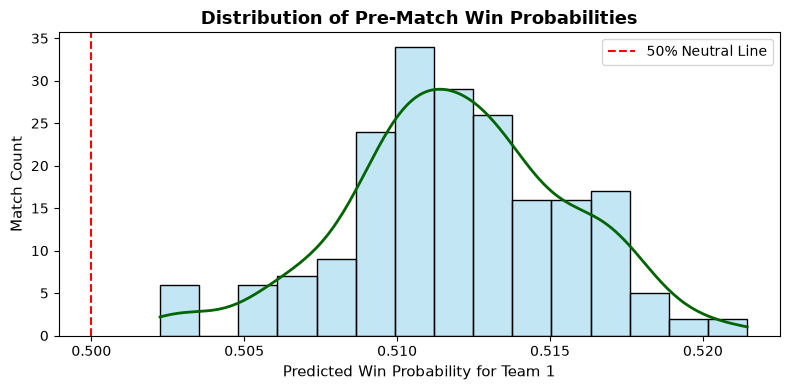

In [18]:
from sklearn.calibration import CalibratedClassifierCV

# Calibrate Random Forest probabilities
calibrated_rf = CalibratedClassifierCV(rf_clf, method='sigmoid', cv=5)
calibrated_rf.fit(X_train_enc, y_train)

# Predict win probability for test matches
win_probs = calibrated_rf.predict_proba(X_test_enc)[:, 1]

# Visualizing Win Probability Distribution 
plt.figure(figsize=(8, 4))
ax = sns.histplot(win_probs, kde=True, color='skyblue', bins=15)

# Find the KDE line object specifically and set its color
for line in ax.lines:
    if line.get_linestyle() != '--':  # Avoid changing your axvline
        line.set_color('darkgreen')
        line.set_linewidth(2)

plt.axvline(0.5, color='red', linestyle='--', label='50% Neutral Line')
plt.title('Distribution of Pre-Match Win Probabilities', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Win Probability for Team 1', fontsize=11)
plt.ylabel('Match Count', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
#EXPLAINABLE AI (SHAP WATERFALLS PLOTS FOR INDIVIDUAL MATCHES)

In [24]:
!pip install shap

   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
    --------------------------------------- 0.8/43.0 MB 287.2 kB/s eta 0:02:27
    --------------------------------------- 0.8/43.0 MB 287.2 kB/s eta 0:02:27
    --------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


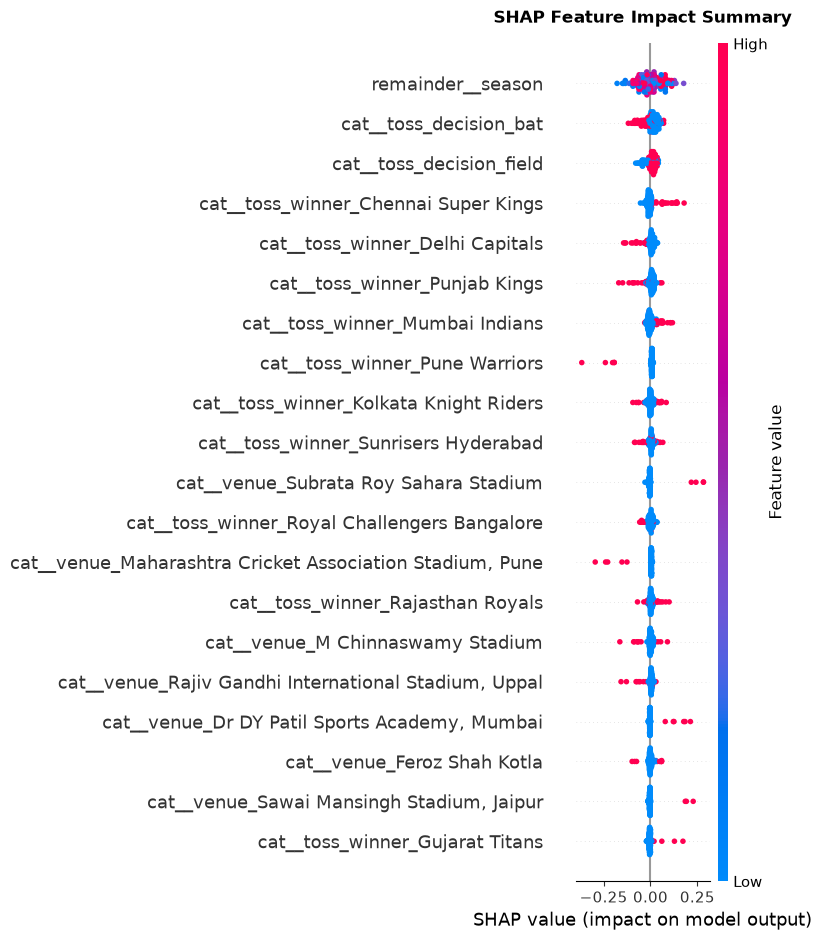

In [21]:
import shap

# 1. Initialize TreeExplainer
explainer = shap.TreeExplainer(rf_clf)

# 2. Compute SHAP values
shap_values = explainer(X_test_enc)

# Handle potential feature name extraction
try:
    feature_names = preprocessor_clf.get_feature_names_out()
except AttributeError:
    feature_names = X_test_enc.columns if hasattr(X_test_enc, 'columns') else None

# 3. Plot SHAP Summary
plt.figure(figsize=(10, 6))

# If shap_values is Explanation object vs raw array
if isinstance(shap_values, shap.Explanation):
    # For binary classification, slice the positive class (class 1)
    if len(shap_values.shape) == 3:  
        shap.summary_plot(shap_values[:, :, 1], feature_names=feature_names, show=False)
    else:
        shap.summary_plot(shap_values, feature_names=feature_names, show=False)
else:
    # Legacy list format fallback
    vals = shap_values[1] if isinstance(shap_values, list) else shap_values
    shap.summary_plot(vals, X_test_enc, feature_names=feature_names, show=False)

plt.title("SHAP Feature Impact Summary", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [22]:
#INTERACTIVE MATCH PREDICTIVE FUNCTION

In [23]:
def predict_match_outcome(team1, team2, venue, toss_winner, toss_decision, season=2024):
    """
    Custom function to simulate a match setup and print formatted pre-match prediction.
    """
    input_data = pd.DataFrame([{
        'venue': venue,
        'toss_winner': toss_winner,
        'toss_decision': toss_decision,
        'team1': team1,
        'team2': team2,
        'season': season
    }])
    
    # Transform input
    input_enc = preprocessor_clf.transform(input_data)
    
    # Predict Probability
    prob_team1 = calibrated_rf.predict_proba(input_enc)[0][1] * 100
    prob_team2 = 100 - prob_team1
    
    predicted_winner = team1 if prob_team1 >= 50 else team2
    confidence = max(prob_team1, prob_team2)
    
    print("=" * 45)
    print(f"   PRE-MATCH PREDICTION: {team1} vs {team2}")
    print("=" * 45)
    print(f" Venue:         {venue}")
    print(f" Toss Winner:   {toss_winner} ({toss_decision})")
    print("-" * 45)
    print(f" {team1} Win Probability: {prob_team1:.1f}%")
    print(f" {team2} Win Probability: {prob_team2:.1f}%")
    print("-" * 45)
    print(f" PREDICTED WINNER: {predicted_winner} ({confidence:.1f}% Confidence)")
    print("=" * 45)

# Example execution
predict_match_outcome('Mumbai Indians', 'Chennai Super Kings', 'Wankhede Stadium', 'Mumbai Indians', 'field')

   PRE-MATCH PREDICTION: Mumbai Indians vs Chennai Super Kings
 Venue:         Wankhede Stadium
 Toss Winner:   Mumbai Indians (field)
---------------------------------------------
 Mumbai Indians Win Probability: 51.1%
 Chennai Super Kings Win Probability: 48.9%
---------------------------------------------
 PREDICTED WINNER: Mumbai Indians (51.1% Confidence)
